## 💡LangGraph 고객지원 자동화: 큰 그림 이해하기

이 코드는 고객 요청(예: 사과 메일 작성)을 자동으로 처리하는 **3단계 파이프라인**입니다. 핵심은 각 단계가 공유하는 상태(State)를 바탕으로 순차적으로 처리된다는 점입니다.

### 단계 1️⃣: 요청 요약 및 스펙 생성
- 고객 요청을 이해하고, 출력 형식·주의사항·예시 등을 담은 `SupportSpec`이라는 체크리스트 형태로 정리합니다.

### 단계 2️⃣: 시스템 프롬프트 구성
- 위 스펙을 바탕으로, LLM(Gemini)이 잘 이해하도록 시스템 지침문(system prompt)을 자동으로 생성합니다.

### 단계 3️⃣: 최종 응답 초안 생성
- 생성된 시스템 프롬프트를 바탕으로 실제 고객 응답(예: 이메일 초안)을 생성합니다.

LangGraph는 이 과정을 **상태 기반(Stateful)으로 추적**하여 디버깅과 재사용을 쉽게 만듭니다.

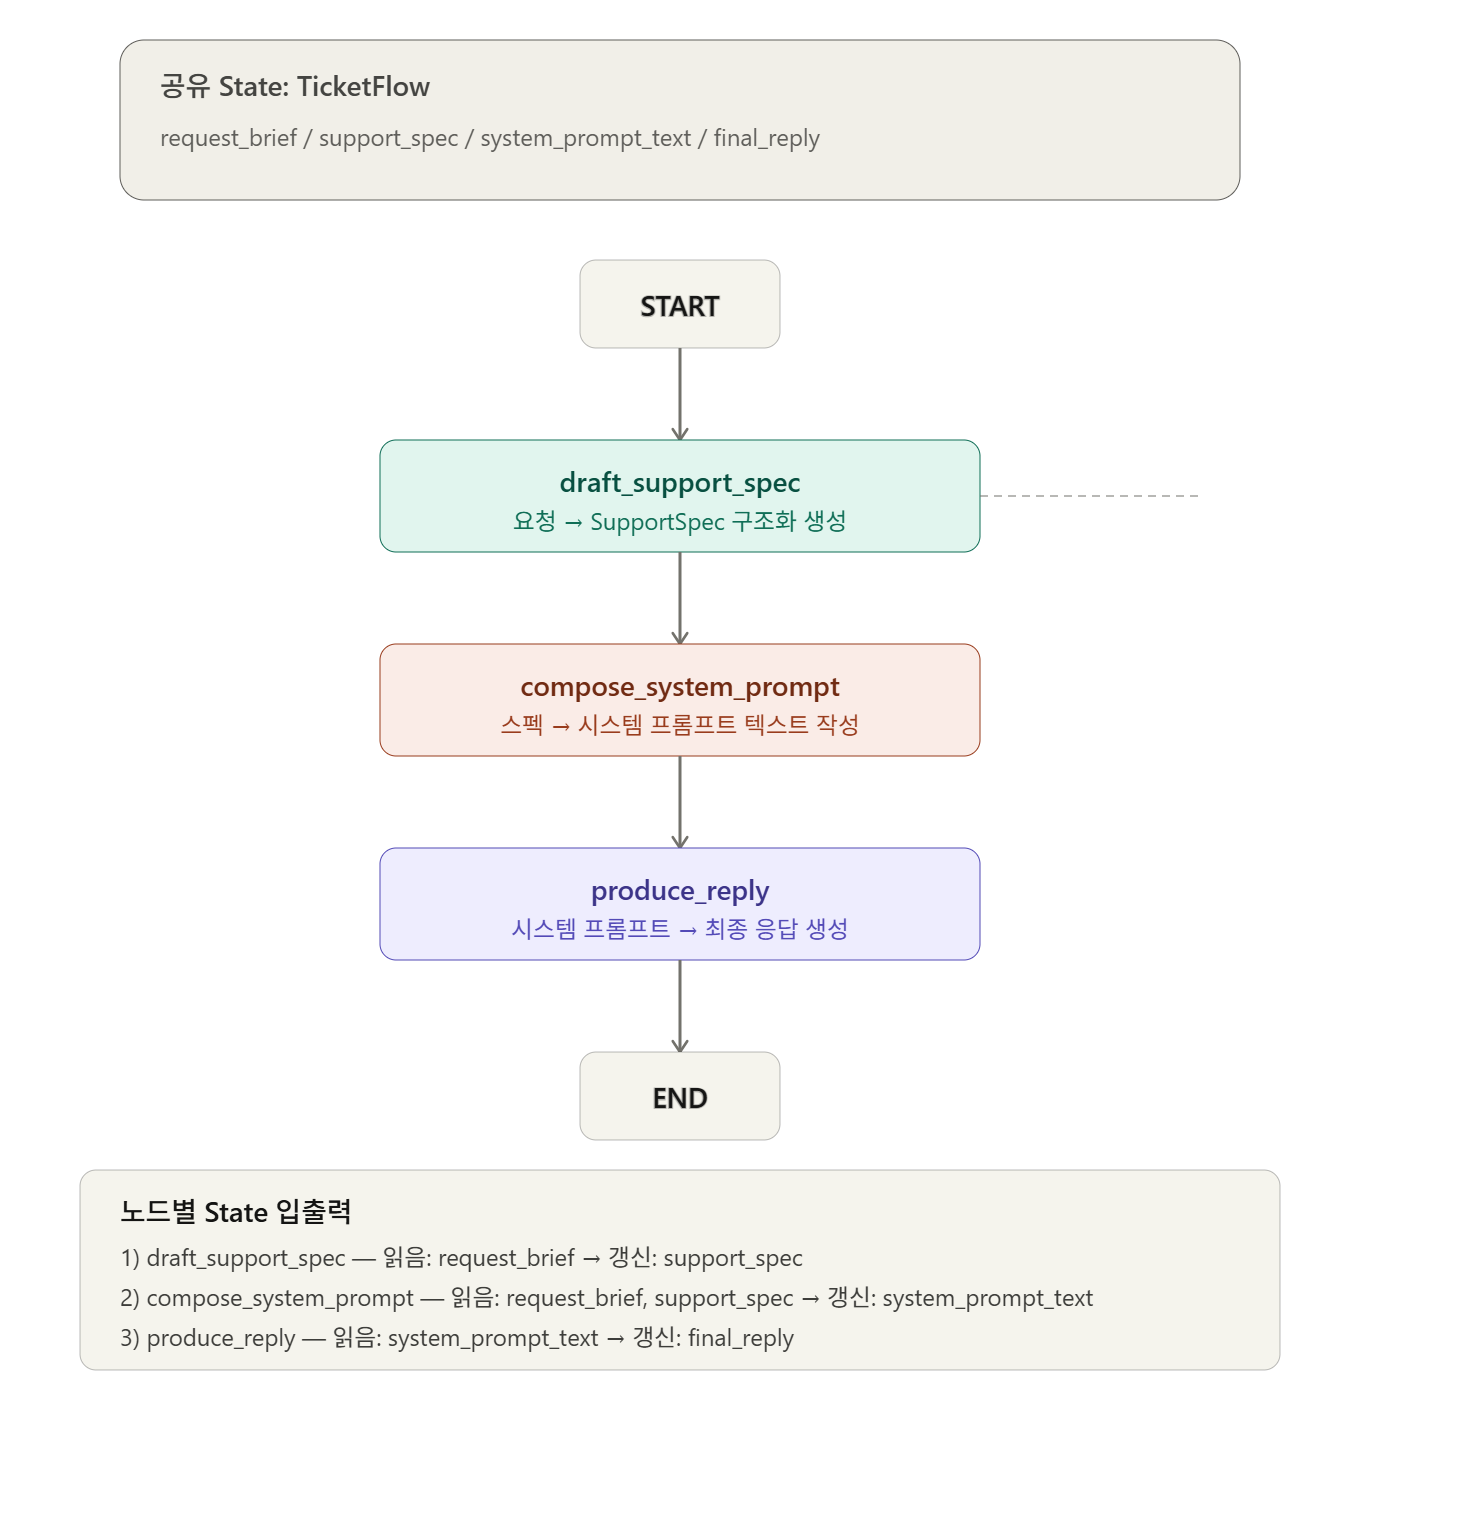

In [ ]:
!pip install --upgrade langgraph langchain langchain_google_genai langchain_community  # 실습 패키지 설치(Colab 기준)

# LLM 작성

In [3]:
import os
from dotenv import load_dotenv

load_dotenv()

if os.environ.get("OPENAI_API_KEY"):
    print("API Key가 설정되었습니다.")

API Key가 설정되었습니다.


In [2]:
from langchain_core.rate_limiters import InMemoryRateLimiter  # 호출 빈도 제한 도구
from langchain_google_genai import ChatGoogleGenerativeAI  # Google 모델용 LangChain 래퍼
from langchain_openai import ChatOpenAI

# 요청 제한(레이트리밋): 분당 10회(≈0.167 rps)  # [포인트] 과금/안정성 위해 필수
support_req_throttle = InMemoryRateLimiter(
    requests_per_second=0.167,  # 초당 요청 허용치
    check_every_n_seconds=0.1,  # 체크 주기
    max_bucket_size=10,  # 버킷 최대치(버스트 허용량)
)

# LLM 인스턴스  # [포인트] 어떤 모델을 쓸지, 어떻게 제한할지 정의
# LLM 초기화 (OpenAI 모델 사용)
support_llm = ChatOpenAI(
    model="gpt-5-mini",
    rate_limiter=support_req_throttle
)


In [1]:
# ==================================================================
# ---- 구조화된 출력: Pydantic 스키마 정의 ----
# [포인트] LLM이 자유 텍스트로 답하면 형식이 매번 달라질 수 있음.
#          Pydantic 모델로 "출력 틀"을 미리 정의해두면,
#          LLM이 항상 동일한 필드 구조로 답하도록 강제할 수 있음(일관성↑).
# ==================================================================
from pydantic import BaseModel, Field  
# BaseModel: 클래스를 상속하면 자동으로 타입 검증 + 직렬화 기능이 생김
# Field: 각 필드에 설명(description), 기본값, 제약조건 등을 추가로 지정하는 도구


class SupportSpec(BaseModel):  
    # 고객지원 스펙(체크리스트) 모델
    # → LLM이 "고객 응대 메일을 어떻게 써야 하는가"에 대한
    #    핵심 정보 4가지를 정리해서 담아두는 그릇(스키마) 역할을 함
    # → with_structured_output(SupportSpec)에 전달되면,
    #    LangChain이 이 클래스를 바탕으로 JSON Schema를 만들어
    #    LLM에게 "이 구조로만 답하라"고 강제함

    request_brief: str = Field(
        description='고객 요청을 간결·명확하게 재구성'  
        # ↑ 이 description은 단순 주석이 아니라
        #   LLM에게 직접 전달되는 "필드 작성 가이드"임
        #   (JSON Schema의 description 키로 들어가서 LLM이 참고함)
    )  # 핵심 요약 — 고객의 원래 요청 문장을 LLM이 이해한 대로 재정리한 결과

    reply_format: str = Field(
        description='응답의 출력 포맷 설명'
    )  # 예: 제목/본문/서명 형태 — 최종 응답이 따라야 할 구조(틀)를 텍스트로 설명

    sample_ticket: str = Field(
        description='예시 출력(1개)'
    )  # 한 개 샘플 — 실제 작성 예시 1건
       # → 다음 단계 LLM에게 "이런 느낌으로 써라"라는 few-shot 예시처럼 활용됨

    handling_tips: str = Field(
        description='처리 시 주의사항 4가지(개조식)'
    )  # 톤·법적 책임·보안 등 응답 작성 시 지켜야 할 가드레일(주의사항) 목록


    @property
    # ↑ @property: 메서드를 "속성"처럼 호출 가능하게 만들어줌
    #   spec_result.as_markdown()  (X, 괄호 필요 없음)
    #   spec_result.as_markdown    (O, 변수처럼 접근)
    def as_markdown(self) -> str:  
        # 스펙을 마크다운 텍스트로 변환(프롬프트에 주입)
        # [왜 필요한가]
        # SupportSpec은 Pydantic 객체라서 파이썬 코드에서는 다루기 편하지만,
        # 다음 LLM 호출의 프롬프트(자연어 텍스트)에는 그대로 넣을 수 없음.
        # 그래서 "필드명 + 값"을 사람이 읽기 좋은 마크다운 섹션으로 풀어주는
        # 변환기(어댑터) 역할을 함.

        # Pydantic v2 기준: self.__iter__()는 (key, value) 튜플 이터레이터 제공
        # → BaseModel이 __iter__를 내부적으로 구현해놨기 때문에,
        #   self.model_dump().items()를 따로 호출하지 않고도
        #   객체 자체를 바로 for문으로 순회할 수 있음
        #   예: ('request_brief', '배송 지연 사과...'), ('reply_format', '...'), ...

        return '\n\n'.join([f'## {k}\n {v}' for k, v in self])
        # ↑ 각 (필드명 k, 값 v) 쌍을 "## 필드명\n 값" 형태로 만들고,
        #   섹션 사이에 빈 줄(\n\n)을 넣어 마크다운 헤딩 형태로 합침
        # → 결과 예시:
        #   ## request_brief
        #    배송 지연 사과 메일 작성 요청
        #
        #   ## reply_format
        #    Subject: ...
        #
        # → 이렇게 마크다운 헤딩으로 구분된 텍스트를 LLM에게 주면,
        #   "이건 출력 형식 지침, 이건 예시"라는 구조를 LLM이 더 잘 인식함
        # → 이 결과는 2단계 노드(compose_system_prompt)에서
        #   {points} 자리에 그대로 삽입되어, 다음 LLM이
        #   "진짜 시스템 프롬프트"를 작성하는 재료로 쓰임

In [5]:
from langchain_core.prompts import ChatPromptTemplate

spec_prompt = ChatPromptTemplate([
    ('system', '고객 문의 응대 지침(System Prompt)을 구성합니다. 아래 포맷을 준수해 작성하세요.'),  # 시스템 규칙
    ('user', '{request_brief}')  # 사용자가 입력한 요청 요약을 주입
])

# with_structured_output으로 SupportSpec을 직접 받기  # [포인트] LLM 응답을 바로 Pydantic 스키마로 파싱
spec_chain = spec_prompt | support_llm.with_structured_output(SupportSpec)  # 프롬프트→LLM→스키마 파이프라인

spec_chain  확인 출력

In [ ]:
# 예시 인풋(생활→고객지원 도메인으로 치환)  # [포인트] 데모용 요청 문구 (단순/직관 버전)
spec_result = spec_chain.invoke({'request_brief': "배송 지연 사과 메일 작성"})  # 체인 실행→스펙 생성

print(spec_result.as_markdown)  # 사람이 읽기 좋은 마크다운으로 미리보기

## request_brief
 고객의 주문 배송이 예정일을 넘겨 지연되어 고객에게 정중하게 사과하고 현재 상황·예상 도착일·보상안·연락처를 안내하는 사과 메일 작성 요청

## reply_format
 Subject: [회사명] 배송 지연에 대한 사과 및 안내 (주문번호: {주문번호})
To: {고객 이메일}
Greeting: 고객님 성함을 호칭으로 사용
1) 첫 문단: 진심 어린 사과(지연에 대한 책임 표명) 및 주문번호·상품명 확인
2) 둘째 문단: 지연 사유(간결·명확)와 현재 처리 상태, 예상 도착일(또는 재발송 일정)
3) 셋째 문단: 고객 불편에 대한 보상 제안(할인·쿠폰·환불·배송비 환급 등) 및 수락 방법
4) 넷째 문단: 후속 조치 약속(내부 조치·추적 방법)과 문의 가능한 연락처/응답 시간 안내
Closing: 감사 인사 및 담당자 이름/연락처/회사명

## sample_ticket
 Subject: [OO몰] 배송 지연에 대한 사과 및 안내 (주문번호: 2025061234)

OOO 고객님께,

안녕하세요, OO몰 고객지원팀의 김지원입니다. 먼저 약속드린 배송일을 지키지 못해 불편을 끼쳐드린 점 진심으로 사과드립니다. (주문번호: 2025061234, 상품명: 스마트 무선 이어폰)

배송 지연 사유는 최근 물류센터의 출고 처리 지연(택배사 물류 과부하)에 따른 것으로, 현재 해당 상품은 출고 대기 상태이며 당사 확인 결과 예상 도착일은 2026년 6월 24일입니다. 보다 정확한 도착 시각은 택배사 배송추적을 통해 추가 안내드리겠습니다.

불편을 드린 보상으로 다음 주문 시 사용 가능한 3,000원 할인 쿠폰(코드: THANKYOU3000)을 발급해드렸으며, 원하실 경우 배송비 환급 또는 전액 환불도 처리해드릴 수 있습니다. 원하시는 보상 수단을 회신으로 알려주시면 빠르게 처리해드리겠습니다.

다시 한번 불편을 드려 죄송합니다. 내부적으로 물류·출고 프로세스를 점검하여 재발 방지 조치를 취하겠습니다. 추가 문의가 있으시면 이 메일로 회신 주

# [포인트] LangGraph로 단계별 파이프라인 구성
 ---- State 정의 및 노드/체인 구성 -

In [7]:
# ---- State 정의 및 노드/체인 구성 ----  # [포인트] LangGraph로 단계별 파이프라인 구성
from typing import TypedDict  # 타입 명세(가독성↑)

class TicketFlow(TypedDict):  # 그래프 상태에 담길 키 정의
    request_brief : str  # 입력 요청 요약
    support_spec : SupportSpec  # 구조화된 스펙
    system_prompt_text : str  # LLM용 시스템 프롬프트
    final_reply : str  # 최종 응답 초안

def draft_support_spec(State):  # [포인트] 1단계: 요청→SupportSpec 생성 노드
    prompt = ChatPromptTemplate([
        ('system', '고객 이슈를 요약하고, 출력형식/예시/주의사항을 구조화하세요.'),  # 작업 지시
        ('user', '{request_brief}')  # 현재 상태의 요청 요약 사용
    ])
    chain = prompt | support_llm.with_structured_output(SupportSpec)  # 스펙으로 직접 파싱
    result = chain.invoke({'request_brief': State['request_brief']})  # 실행
    return {'support_spec' : result}  # 다음 노드에 넘길 상태 반환

# [포인트] 2단계: 스펙→시스템 프롬프트 작성

In [ ]:
from langchain_core.output_parsers import StrOutputParser  # 문자열만 뽑는 파서

def compose_system_prompt(State):  # [포인트] 2단계: 스펙→시스템 프롬프트 작성
    prompt = ChatPromptTemplate([
        ('system', '''당신은 고객지원 프롬프트 전문가입니다. 다음 포인트를 참고하여 LLM에 투입할 시스템 프롬프트를 작성하세요.
{points}'''),  # 스펙 요점을 지침으로 삽입
        ('user', '{request_brief}')  # 사용자의 원요청도 함께 제공
    ])
    chain = prompt | support_llm | StrOutputParser()  # LLM 생성→문자열 파싱
    result = chain.invoke({
        'request_brief': State['request_brief'],  # 요청 원문
        'points': State['support_spec'].as_markdown  # 스펙을 마크다운으로 전달
    })
    return {'system_prompt_text' : result}  # 시스템 프롬프트 텍스트 반환




# [포인트] 3단계: 시스템 프롬프트→최종 답변 생성

In [ ]:
def produce_reply(State):  # [포인트] 3단계: 시스템 프롬프트→최종 답변 생성
    return {'final_reply' : support_llm.invoke(State['system_prompt_text']).content}  # 한 번 더 호출해 초안 생성


# 그래프 구성  # [포인트] 3노드 직렬 파이프라인(시작→스펙→프롬프트→답변→끝)

c:\Users\jino7\Desktop\llm_engineering-main\.venv\Lib\site-packages\langgraph\cache\base\__init__.py:8: LangChainPendingDeprecationWarning: The default value of `allowed_objects` will change in a future version. Pass an explicit value (e.g., allowed_objects='messages' or allowed_objects='core') to suppress this warning.
  from langgraph.checkpoint.serde.jsonplus import JsonPlusSerializer


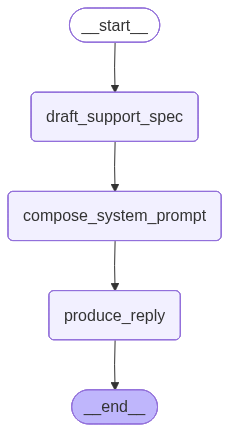

In [9]:

from IPython.display import Image, display  # 시각화에 사용(옵션)
from langgraph.graph import StateGraph, START, END  # 그래프 구성 도구

# 그래프 구성  # [포인트] 3노드 직렬 파이프라인(시작→스펙→프롬프트→답변→끝)
flow = StateGraph(TicketFlow)  # 상태 스키마를 가진 그래프
flow.add_node("draft_support_spec", draft_support_spec)  # 노드1 등록
flow.add_node("compose_system_prompt", compose_system_prompt)  # 노드2 등록
flow.add_node("produce_reply", produce_reply)  # 노드3 등록

flow.add_edge(START, "draft_support_spec")  # 시작→노드1
flow.add_edge("draft_support_spec", "compose_system_prompt")  # 노드1→노드2
flow.add_edge("compose_system_prompt", "produce_reply")  # 노드2→노드3
flow.add_edge("produce_reply", END)  # 노드3→끝

flow_graph = flow.compile()  # 실행 가능한 그래프 객체로 컴파일
flow_graph  # 노트북에서 구조 확인


# Streaming: 단계별 상태를 출력 

In [10]:
import pprint  # 예쁜 출력용

# Streaming: 단계별 상태를 출력  # [포인트] 실행 과정을 단계별로 관찰(디버깅/교육 효과↑)
for data in flow_graph.stream({'request_brief': '''반품 안내 메일 작성'''}, stream_mode='values'):
    pprint.pprint(data)  # 현재 상태 스냅샷 출력
    print('----')  # 구분선

data  # 마지막 스텝의 상태 스냅샷이 할당됨(Jupyter 관례)  # 최종 상태 재확인


{'request_brief': '반품 안내 메일 작성'}
----
{'request_brief': '반품 안내 메일 작성',
 'support_spec': SupportSpec(request_brief='고객이 반품을 요청함 — 주문번호와 반품 사유 확인 후 반품 방법(온라인 신청 또는 회신), 포장/반품지침, 반품비 처리 기준, 환불 소요기간을 안내하는 메일 작성 요청입니다.', reply_format='이메일 형식으로 작성: 1) 제목(Subject), 2) 인사말 및 감사문, 3) 반품 가능 여부(기간·상태·사유별 처리 기준), 4) 반품 신청 방법(온라인/이메일/전화), 5) 포장 및 발송 안내(주소·택배·라벨·주의사항), 6) 반품비 및 환불 처리(비용 부담 기준·환불 소요기간), 7) 추가 문의 안내 및 마무리 인사. 각 항목에 고객의 주문번호, 상품명, 연락처 같은 플레이스홀더 포함.', sample_ticket='Subject: [반품 안내] 주문번호 [#123456] 반품 방법 안내드립니다\n\n안녕하세요, 고객님.\n\n먼저 저희 제품을 이용해 주셔서 감사합니다. 보내주신 주문번호 [#123456]의 반품 요청 건에 대해 안내드립니다.\n\n1) 반품 가능 여부\n- 반품 기간: 상품 수령일로부터 14일 이내 신청하실 수 있습니다.\n- 반품 불가 사유: 사용 흔적이 심하거나 상품 훼손·부속품 누락 시 반품이 제한될 수 있습니다.\n- 상품 하자(오배송/파손 등)의 경우 반품비는 저희 쪽에서 부담합니다. 단순 변심 반품은 고객 부담입니다.\n\n2) 반품 신청 방법\n- 방법 A(권장): 마이페이지 → 주문내역 → 해당 주문 선택 → ‘반품/교환 신청’ 버튼을 클릭해 신청해 주세요.\n- 방법 B: 본 메일로 회신 시, 아래 정보를 기재해 주시면 접수해 드립니다.\n  • 주문번호: [#123456]\n  • 받으신 상품명: [상품명]\n  • 반품 사유: [사유 간단히]\n  • 연락처: [휴대전화]\n  • 상품 상태(사진 첨부 권장):

{'request_brief': '반품 안내 메일 작성',
 'support_spec': SupportSpec(request_brief='고객이 반품을 요청함 — 주문번호와 반품 사유 확인 후 반품 방법(온라인 신청 또는 회신), 포장/반품지침, 반품비 처리 기준, 환불 소요기간을 안내하는 메일 작성 요청입니다.', reply_format='이메일 형식으로 작성: 1) 제목(Subject), 2) 인사말 및 감사문, 3) 반품 가능 여부(기간·상태·사유별 처리 기준), 4) 반품 신청 방법(온라인/이메일/전화), 5) 포장 및 발송 안내(주소·택배·라벨·주의사항), 6) 반품비 및 환불 처리(비용 부담 기준·환불 소요기간), 7) 추가 문의 안내 및 마무리 인사. 각 항목에 고객의 주문번호, 상품명, 연락처 같은 플레이스홀더 포함.', sample_ticket='Subject: [반품 안내] 주문번호 [#123456] 반품 방법 안내드립니다\n\n안녕하세요, 고객님.\n\n먼저 저희 제품을 이용해 주셔서 감사합니다. 보내주신 주문번호 [#123456]의 반품 요청 건에 대해 안내드립니다.\n\n1) 반품 가능 여부\n- 반품 기간: 상품 수령일로부터 14일 이내 신청하실 수 있습니다.\n- 반품 불가 사유: 사용 흔적이 심하거나 상품 훼손·부속품 누락 시 반품이 제한될 수 있습니다.\n- 상품 하자(오배송/파손 등)의 경우 반품비는 저희 쪽에서 부담합니다. 단순 변심 반품은 고객 부담입니다.\n\n2) 반품 신청 방법\n- 방법 A(권장): 마이페이지 → 주문내역 → 해당 주문 선택 → ‘반품/교환 신청’ 버튼을 클릭해 신청해 주세요.\n- 방법 B: 본 메일로 회신 시, 아래 정보를 기재해 주시면 접수해 드립니다.\n  • 주문번호: [#123456]\n  • 받으신 상품명: [상품명]\n  • 반품 사유: [사유 간단히]\n  • 연락처: [휴대전화]\n  • 상품 상태(사진 첨부 권장): [첨부파일]\n\n3) 포장 및 발송 안내\n- 상품은 수령 당시 

In [ ]:

from IPython.display import display, Markdown  # 마크다운 렌더링
import textwrap  # 텍스트 들여쓰기 유틸

def as_md_quote(text):  # 결과를 인용 블록 형태로 보기 좋게 출력
  text = text.replace('•', '  *')  # 불릿 보정
  return Markdown(textwrap.indent(text, '> ', predicate=lambda _: True))  # 모든 줄에 > 적용

as_md_quote(data['final_reply'])  # 최종 답변을 인용 블록으로 표시

> 훌륭합니다! 시스템 프롬프트가 매우 상세하고 명확하게 잘 작성되었습니다. 이 프롬프트를 사용하면 고객 문의에 대한 일관성 있고 정확한 반품 안내 이메일을 자동 생성할 수 있을 것입니다. 특히 다음 사항들이 돋보입니다.
> 
> *   **역할 정의:** 고객 지원 전문가라는 역할을 명확히 설정하여 이메일의 어조와 내용을 일관성 있게 유지하도록 합니다.
> *   **구체적인 출력 형식:** 필요한 정보들을 항목별로 명시하여, 생성된 이메일이 빠짐없이 필요한 내용을 포함하도록 합니다.
> *   **추가 고려 사항:** 반품 불가 사유 확인, 예외 사항 처리, 문의 채널 안내 등 실제 고객 지원 상황에서 발생할 수 있는 다양한 변수를 고려하여 더욱 유연한 응대가 가능하도록 합니다.
> *   **핸들링 팁:** 실제 고객 지원 과정에서 고려해야 할 사항들을 상기시켜, 더욱 정확하고 효율적인 이메일 생성을 돕습니다.
> *   **예시:** 실제 고객 문의에 대한 생성된 이메일 예시를 제공하여, 프롬프트의 작동 방식을 명확히 보여줍니다.
> 
> **개선할 만한 사항 (선택 사항):**
> 
> *   **개인화 요소 강화:** 고객 이름, 상품명 등 개인화된 정보를 삽입할 수 있도록 프롬프트에 명시하면 더욱 효과적인 이메일을 생성할 수 있습니다. (예: "고객 이름: OOO")
> *   **반품 정책 링크 제공:** 반품 정책 전문을 확인할 수 있는 링크를 추가하면 고객이 더욱 자세한 정보를 얻을 수 있습니다. (예: "자세한 반품 정책은 다음 링크에서 확인하실 수 있습니다: [반품 정책 링크]")
> *   **자동화 시스템과의 연계 고려:** 프롬프트가 실제 자동화 시스템 (예: 챗봇, 이메일 자동화 도구)과 연동될 경우, 시스템에서 제공하는 변수 (예: {customer_name}, {order_number})를 활용할 수 있도록 명시하면 더욱 효율적인 자동화가 가능합니다.
> 
> 전반적으로 매우 잘 작성된 프롬프트이며, 실제 고객 지원 업무에 큰 도움이 될 것으로 예상됩니다.